# Attention allocation

Do people look more at the answer they end up choosing? This notebook uses Study 1 (360 participants, 19,436 trials) and its word-level table, where each area's measurements (dwell time, skip rate, pupil size, ...) are copied onto every word of that area. For the trials where one answer (A, B, C or D) was chosen, it shows the mean of one measurement on each of the four answers, first as bar charts and then split by where each answer sat on the screen, and ends with a mixed model that tests which answers differ. Answers are named by meaning: `answer_A` is always the correct one, B to D are the wrong ones, and their screen positions are shuffled from trial to trial. The error bars on the bar charts are 95% bootstrap intervals over trials, which treat every trial as independent, although trials from the same participant are alike. Everything here is for all participants together; the `run_all_*` functions also draw hunters and gatherers separately.

In [1]:
import sys
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "__init__.py").exists())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from src.lib.plotting.output import set_output_defaults
set_output_defaults(save=False)   # this notebook only shows; it saves nothing

import matplotlib.pyplot as plt
import pandas as pd
from src.config import columns as Con
from src.config.datasets import dataset
from src.features.build import load_model_input
from src.analyses.attention_allocation.plots import (
    plot_area_ci_bar,
    matrix_plot_ABCD,
    plot_pairwise_significance_heatmap,
)
from src.analyses.attention_allocation.stats import mixed_area_analysis

df = load_model_input(dataset("l1"))   # Study 1, one row per word on the answer screen

  grains: interest_areas (760628, 23), areas_answers (97180, 19), trials (19436, 89)


## The input

Each area's measurements are the same on every word of the area, so the functions below first reduce the table to one row per trial and area. Here is one trial, reduced that way: the question and the four answers, with the answer's meaning (`area_label`), its place on the screen (`area_screen_loc`) and the answer chosen.

The second table counts trials by the answer chosen. Most trials are answered correctly (A), so the figures for B, C and D rest on far fewer trials.

In [2]:
cols = [Con.PARTICIPANT_ID, Con.TRIAL_ID, Con.AREA_LABEL_COLUMN, Con.AREA_SCREEN_LOCATION,
        Con.SELECTED_ANSWER_LABEL_COLUMN, Con.MEAN_DWELL_TIME, Con.SKIP_RATE]
one_trial = (df[Con.PARTICIPANT_ID] == df[Con.PARTICIPANT_ID].iloc[0]) & (df[Con.TRIAL_ID] == df[Con.TRIAL_ID].iloc[0])
display(df.loc[one_trial, cols].drop_duplicates().reset_index(drop=True).round(3))

trials = df.drop_duplicates([Con.PARTICIPANT_ID, Con.TRIAL_ID])
trials[Con.SELECTED_ANSWER_LABEL_COLUMN].value_counts().rename("trials").to_frame()

,participant_id,TRIAL_INDEX,area_label,area_screen_loc,selected_answer_label,mean_dwell_time,skip_rate
0,l42_2070,4,question,question,A,41.250,0.750
1,l42_2070,4,answer_B,answer_0(top),A,173.000,0.429
2,l42_2070,4,answer_C,answer_1(left),A,147.143,0.571
3,l42_2070,4,answer_D,answer_2(right),A,208.714,0.429
4,l42_2070,4,answer_A,answer_3(bottom),A,226.750,0.250


,trials
selected_answer_label,
A,16339
B,1744
C,942
D,411


## The mean on each answer, by the answer chosen

`plot_area_ci_bar` takes the trials where one answer was chosen and draws the mean of one measurement on each answer. Below: mean dwell time per word (in ms; words never looked at count as 0), once for each chosen answer. If people look more at what they choose, the chosen answer's bar stands out in each chart. The table holds the numbers behind the bars: mean, standard deviation and the number of trials.

`run_all_area_barplots` draws this for all ten measurements, every chosen answer, and hunters, gatherers and all participants.

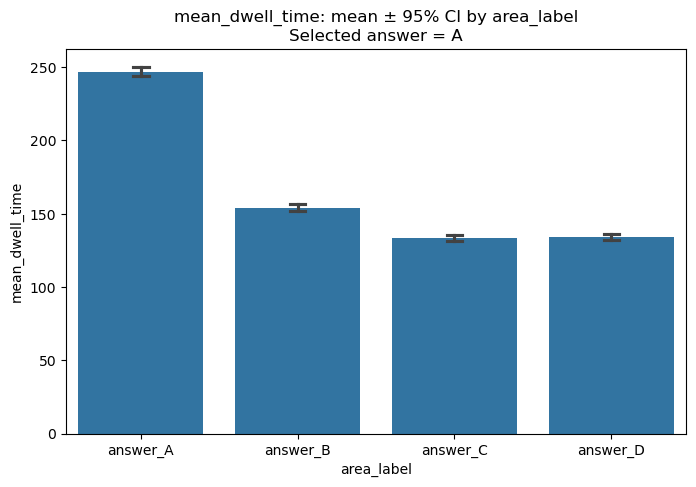

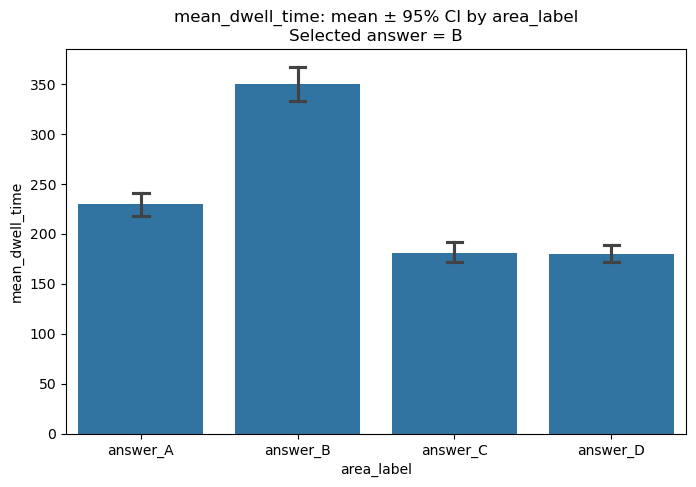

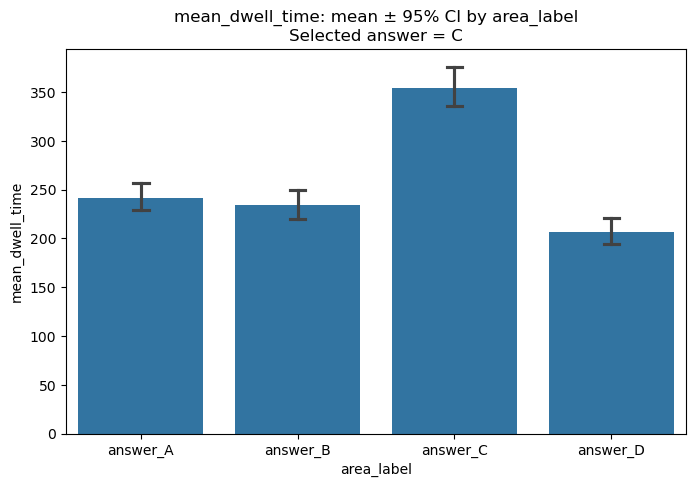

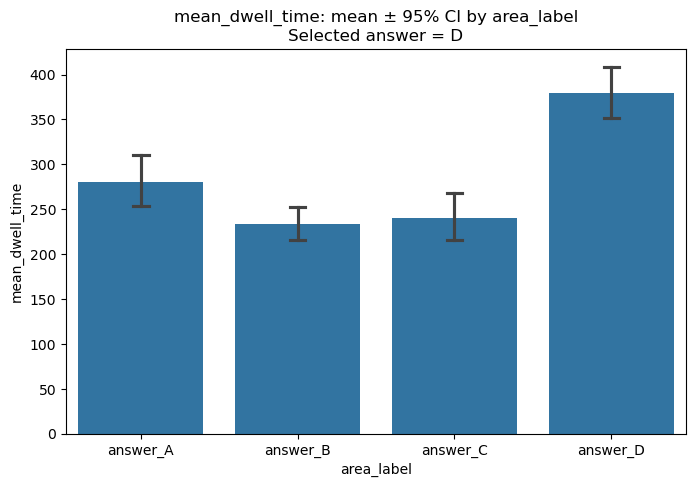

,area_label,mean,sd,n
chosen,,,,
A,answer_A,246.9,216.9,16339
A,answer_B,154.1,150.7,16339
A,answer_C,133.5,129.8,16339
A,answer_D,134.2,127.7,16339
B,answer_A,229.5,238.9,1744
B,answer_B,349.2,352.6,1744
B,answer_C,181.0,200.5,1744
B,answer_D,179.4,175.7,1744
C,answer_A,241.7,225.2,942


In [3]:
summaries = {}
for chosen in ["A", "B", "C", "D"]:
    fig, summaries[chosen] = plot_area_ci_bar(
        df[df[Con.SELECTED_ANSWER_LABEL_COLUMN] == chosen],
        stat_col=Con.MEAN_DWELL_TIME,
        selected=chosen,
        h_or_g="all_participants",
        save=False,
    )
plt.show()
pd.concat(summaries, names=["chosen", "row"]).reset_index("row", drop=True).round(1)

The same chart for a second measurement: skip rate, the share of an area's words never looked at, for the trials where B was chosen. Here a lower bar means more of the answer was read.

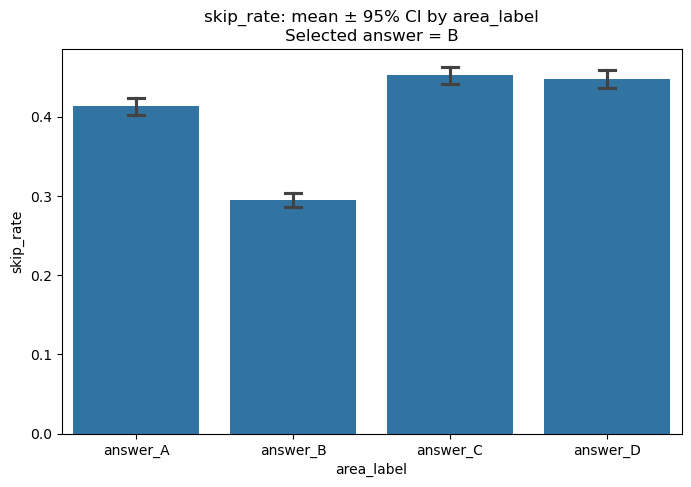

,area_label,mean,sd,n
0,answer_A,0.413,0.250,1744
1,answer_B,0.295,0.207,1744
2,answer_C,0.452,0.238,1744
3,answer_D,0.447,0.239,1744


In [4]:
fig, summary = plot_area_ci_bar(
    df[df[Con.SELECTED_ANSWER_LABEL_COLUMN] == "B"],
    stat_col=Con.SKIP_RATE,
    selected="B",
    h_or_g="all_participants",
    save=False,
)
plt.show()
summary.round(3)

## Answer by screen position

`matrix_plot_ABCD` splits the same means by where each answer was shown. Rows are the answers by meaning, columns the four screen positions, and each cell is the mean over the trials where that answer sat in that position. If the chosen answer's row is high in every column, the extra attention follows the answer, not its place on the screen. Below: mean dwell time, for the trials where A was chosen and where B was chosen, with the question left out.

`drop_questions=False` adds the question's row. `run_all_area_metric_plots` draws every measurement (pupil size in mm here, not z-scored), chosen answer and group, with and without the question.

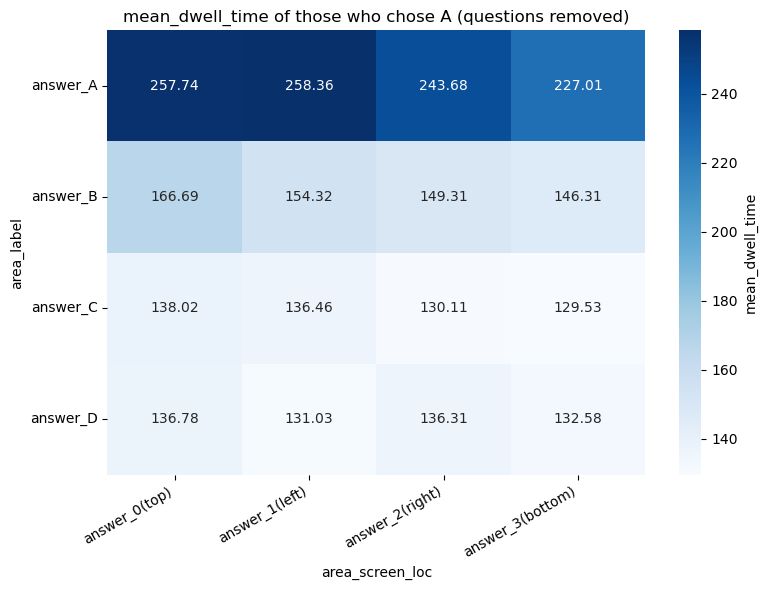

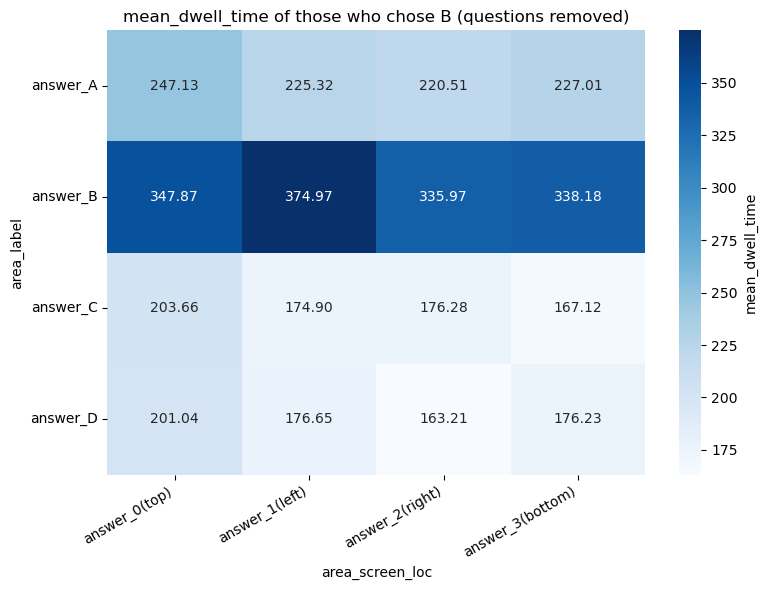

area_screen_loc    answer_0(top)  answer_1(left)  answer_2(right)  \
chosen area_label                                                   
A      answer_A            257.7           258.4            243.7   
       answer_B            166.7           154.3            149.3   
       answer_C            138.0           136.5            130.1   
       answer_D            136.8           131.0            136.3   
B      answer_A            247.1           225.3            220.5   
       answer_B            347.9           375.0            336.0   
       answer_C            203.7           174.9            176.3   
       answer_D            201.0           176.7            163.2   

area_screen_loc    answer_3(bottom)  
chosen area_label                    
A      answer_A               227.0  
       answer_B               146.3  
       answer_C               129.5  
       answer_D               132.6  
B      answer_A               227.0  
       answer_B               338.2  
       answer_C               167.1  
       answer_D               176.2

In [5]:
matrices = {}
for chosen in ["A", "B"]:
    matrices[chosen] = matrix_plot_ABCD(
        df[df[Con.SELECTED_ANSWER_LABEL_COLUMN] == chosen],
        Con.MEAN_DWELL_TIME,
        selected=chosen,
        h_or_g="all_participants",
        drop_questions=True,
        save=False,
    )
pd.concat(matrices, names=["chosen"]).round(1)

## Comparing the answers with mixed models

Which answers differ from each other? Among the trials where one answer was chosen, `mixed_area_analysis` fits the measurement on the four answers, with a random intercept for each participant and one for each trial, and compares every pair of answers with a Holm correction. Below: mean dwell time, for the trials where B was chosen.

`plot_pairwise_significance_heatmap` colours each pair by -log10 of its Holm-adjusted p-value, so the brighter the cell, the smaller the p-value; a pair below 0.05 shows stars and an arrow, ↑ if the row's answer has the higher value. The first table is each answer's estimate with a 95% confidence interval; the second has one row per pair: the difference (first minus second), its p-value before and after the Holm correction, and ★ where it is below 0.05.

`run_all_area_mixed_models` repeats this for every measurement (pupil size z-scored), chosen answer and group.

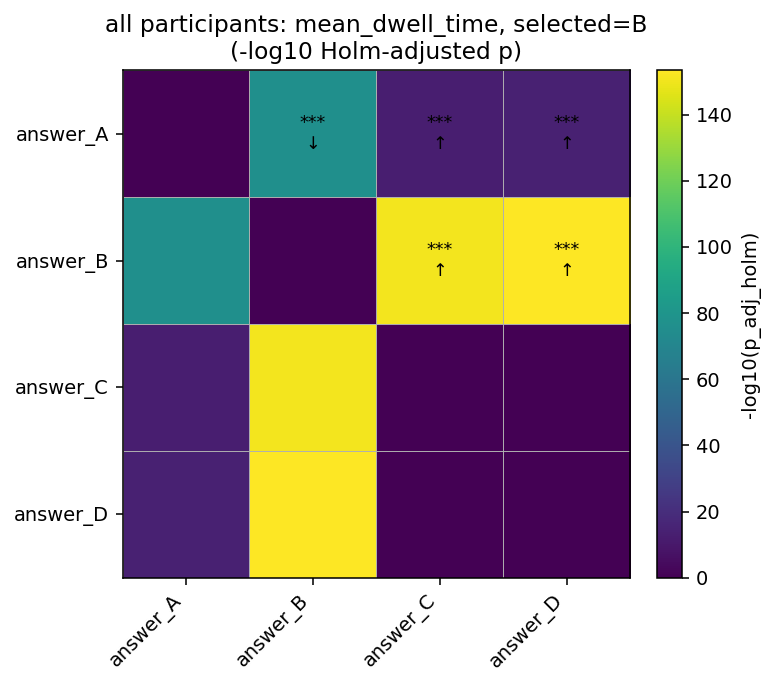

,area,term,estimate,ci_low,ci_high
0,answer_A,C(area_label)[answer_A],228.4,214.9,241.9
1,answer_B,C(area_label)[answer_B],348.1,334.6,361.6
2,answer_C,C(area_label)[answer_C],179.9,166.4,193.4
3,answer_D,C(area_label)[answer_D],178.3,164.8,191.8


,area_i,area_j,diff_i_minus_j,se,t,p_unc,ci_low,ci_high,p_adj_holm,sig
0,answer_A,answer_B,-119.7,6.4,-18.69,5.577458e-78,-132.3,-107.2,2.230983e-77,★
1,answer_A,answer_C,48.5,6.4,7.57,3.664199e-14,35.9,61.0,7.328399e-14,★
2,answer_A,answer_D,50.1,6.4,7.82,5.286661e-15,37.5,62.6,1.585998e-14,★
3,answer_B,answer_C,168.2,6.4,26.27,4.689196e-152,155.6,180.7,2.344598e-151,★
4,answer_B,answer_D,169.8,6.4,26.51,6.766648e-155,157.2,182.3,4.059989e-154,★
5,answer_C,answer_D,1.6,6.4,0.25,8.045158e-01,-11.0,14.1,8.045158e-01,


In [6]:
result, fe_table, pairwise = mixed_area_analysis(
    df[df[Con.SELECTED_ANSWER_LABEL_COLUMN] == "B"],
    stat_col=Con.MEAN_DWELL_TIME,
)
fig = plot_pairwise_significance_heatmap(
    pairwise,
    title=f"all participants: {Con.MEAN_DWELL_TIME}, selected=B\n(-log10 Holm-adjusted p)",
)
plt.show()
display(fe_table.round(1))
pairwise.round({"diff_i_minus_j": 1, "se": 1, "t": 2, "ci_low": 1, "ci_high": 1})